In [1]:
%pip install pandas
%pip install matplotlib
%pip install seaborn

  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.8 MB 8.3 MB/s eta 0:00:02
   -------------- ------------------------- 3.7/9.8 MB 10.0 MB/s eta 0:00:01
   ---------------------- ----------------- 5.5/9.8 MB 9.9 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/9.8 MB 9.5 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.8 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 8.9 MB/s  0:00:01
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.7 MB 7.1 MB/s eta 0:00:02
   --------- ------------------------------ 2.9/12.7 MB 7.3 MB/s eta 0:00:02
   -------------- ------------------------- 4.5/12.7 MB 7.4 MB/s eta 0:00:02
   ------------------- -------------------- 6.3/12.7 MB 7.5 MB/s eta 0:00:01
   ------------------------ ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.5 MB 11.8 MB/s eta 0:00:01
   --------------- ------------------------ 3.7/9.5 MB 9.6 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.5 MB 9.3 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 9.1 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.5 MB 9.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 8.8 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   --------------------- ------------------ 1.3/2.5 MB 7.0 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 7.0 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   -------- ------------------------------- 1.6/7.2 MB 7.3 MB/s eta 0:00:


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("../data/food-texture.csv")

# Rename the index-like column if it exists
if "Unnamed: 0" in df.columns:
    df = df.rename(columns={"Unnamed: 0": "Sample_ID"})

df.head()

,Sample_ID,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143


In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print(df.columns.tolist())

Number of rows: 50
Number of columns: 6
['Sample_ID', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']


In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Sample_ID  50 non-null     str    
 1   Oil        50 non-null     float64
 2   Density    50 non-null     int64  
 3   Crispy     50 non-null     int64  
 4   Fracture   50 non-null     int64  
 5   Hardness   50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB


In [9]:
print(df.isnull().sum())

Sample_ID    0
Oil          0
Density      0
Crispy       0
Fracture     0
Hardness     0
dtype: int64


In [11]:
print( df.duplicated().sum())

0


In [12]:
df.describe()

,Oil,Density,Crispy,Fracture,Hardness
count,50.000000,50.00000,50.000000,50.000000,50.000000
mean,17.202000,2857.60000,11.520000,20.860000,128.180000
std,1.592007,124.49998,1.775571,5.466073,31.127578
min,13.700000,2570.00000,7.000000,9.000000,63.000000
25%,16.300000,2772.50000,10.000000,17.000000,107.250000
50%,16.900000,2867.50000,12.000000,21.000000,126.000000
75%,18.100000,2945.00000,13.000000,25.000000,143.750000
max,21.200000,3125.00000,15.000000,33.000000,192.000000


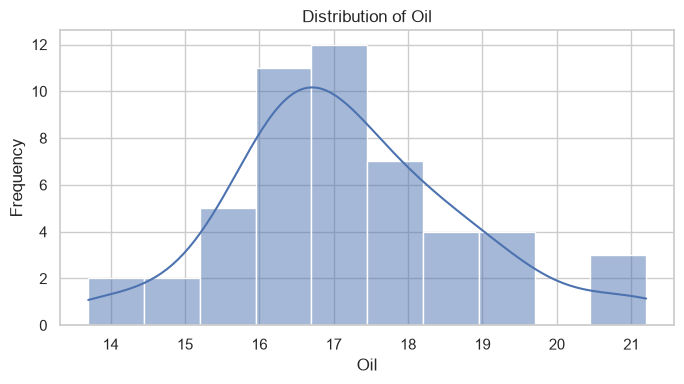

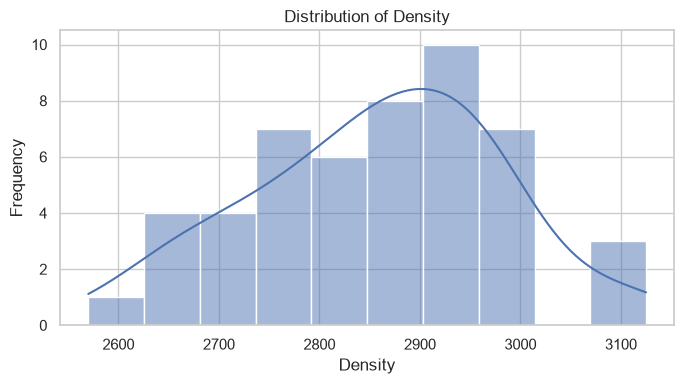

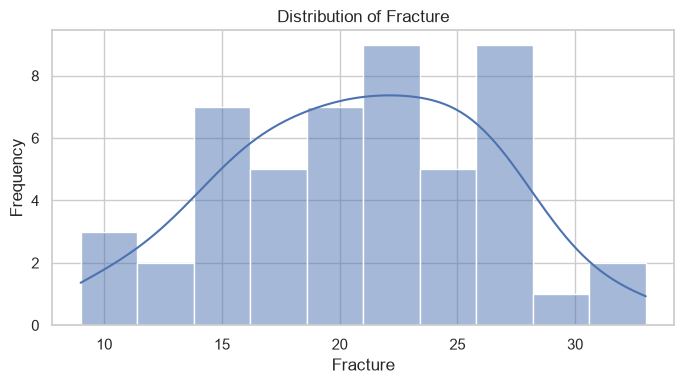

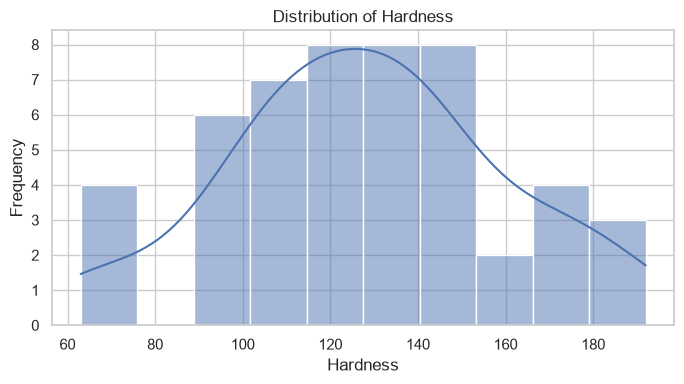

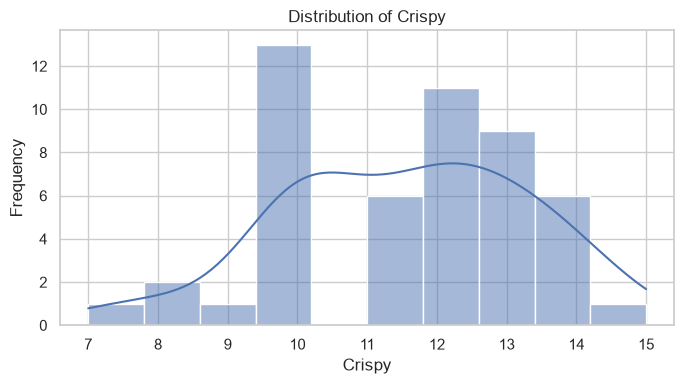

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["Oil", "Density", "Fracture", "Hardness", "Crispy"]

for col in features:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=10
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    
    
    plt.show()

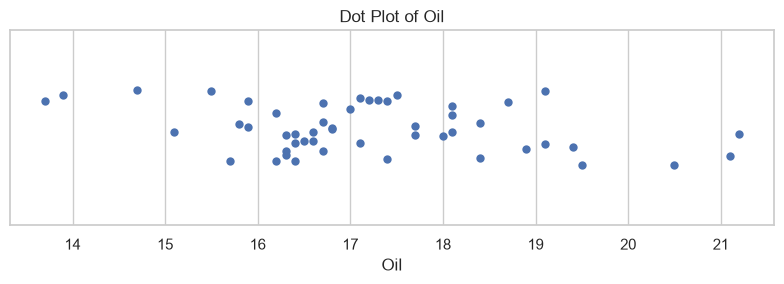

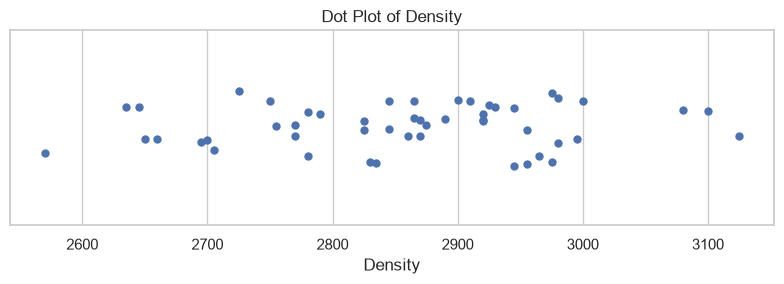

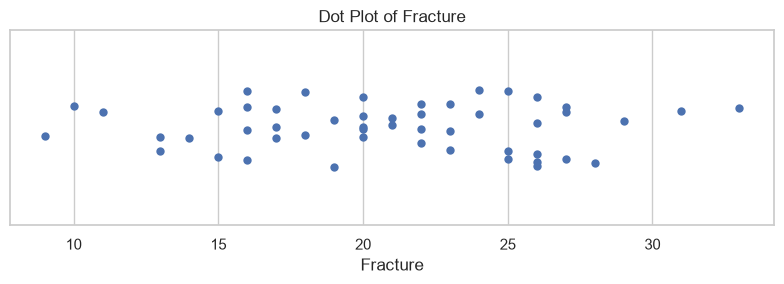

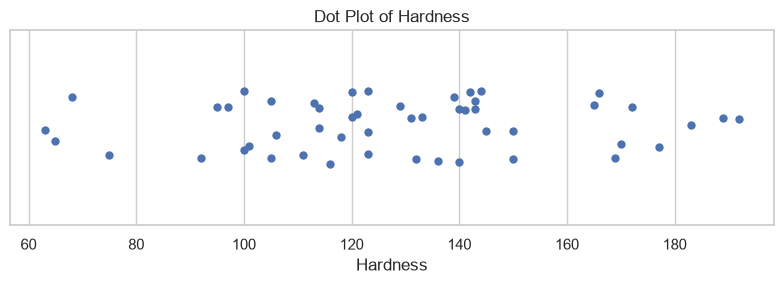

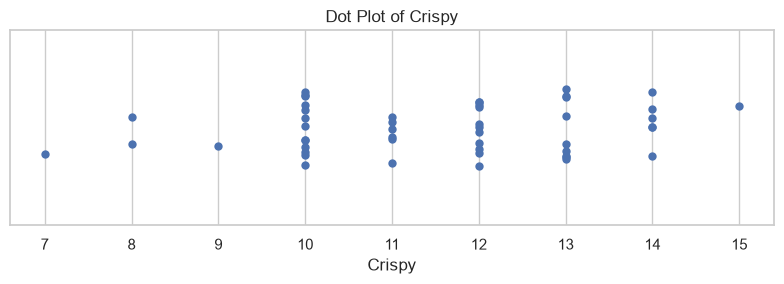

In [18]:
for col in features:
    plt.figure(figsize=(8, 3))

    sns.stripplot(
        data=df,
        x=col,
        jitter=0.2,
        size=6
    )

    plt.title(f"Dot Plot of {col}")
    plt.xlabel(col)
    plt.yticks([])
    plt.tight_layout()
    plt.show()

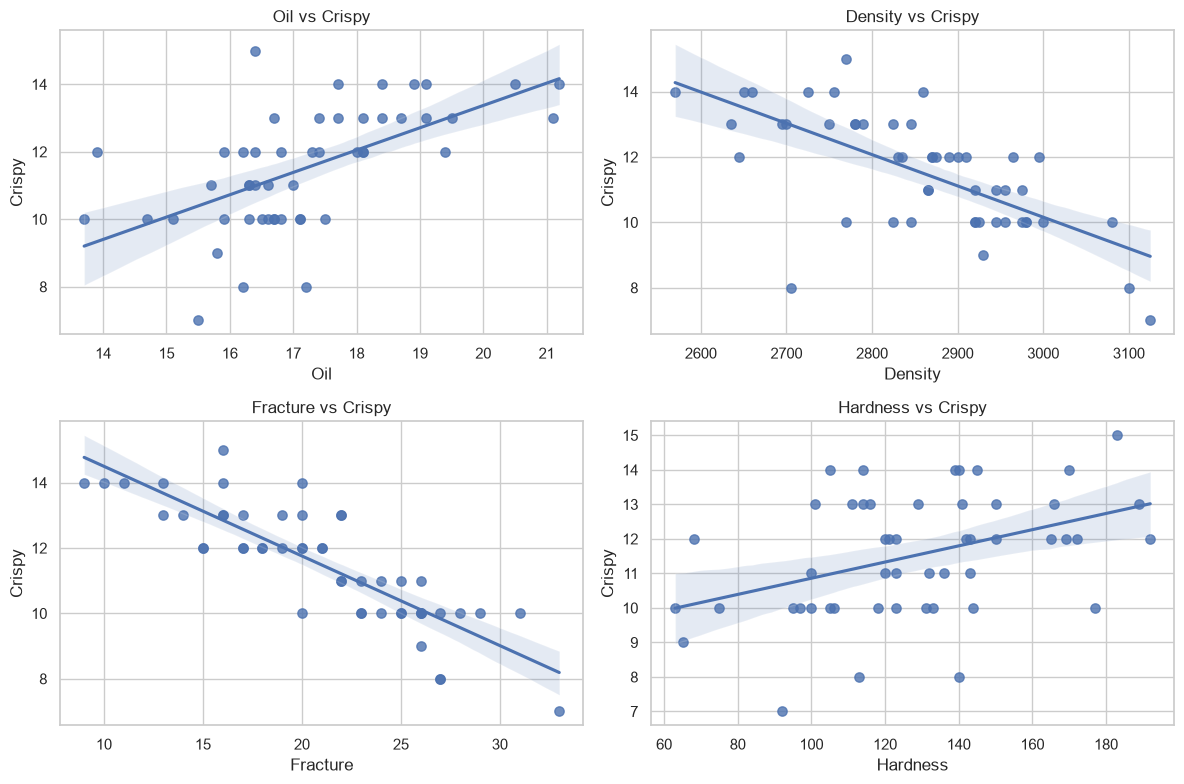

In [ ]:
features = [col for col in ["Oil", "Density", "Fracture", "Hardness"] if col in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(features, axes.flatten()):
    sns.regplot(data=df, x=feature, y="Crispy", ax=ax, scatter_kws={"s": 45})
    ax.set_title(f"{feature} vs Crispy")

for ax in axes.flatten()[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

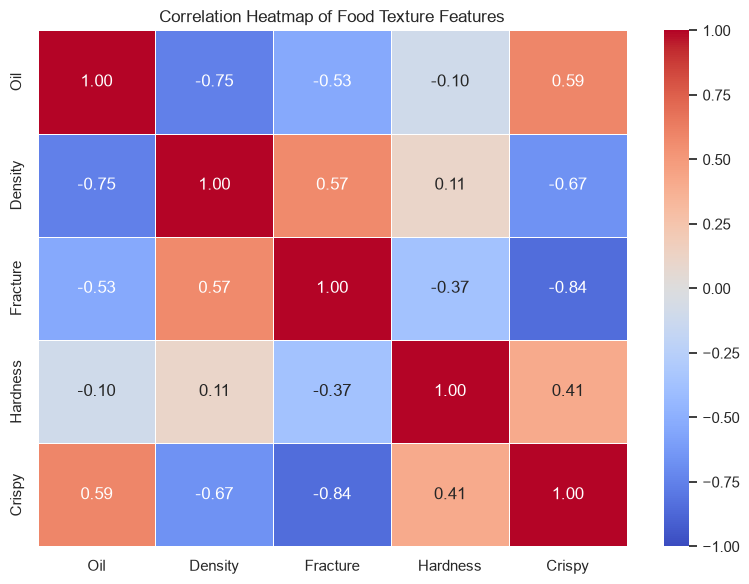

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["Oil", "Density", "Fracture", "Hardness", "Crispy"]

correlation = df[features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Food Texture Features")
plt.tight_layout()
plt.show()

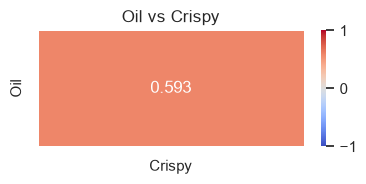

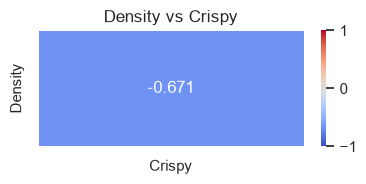

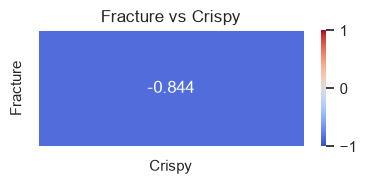

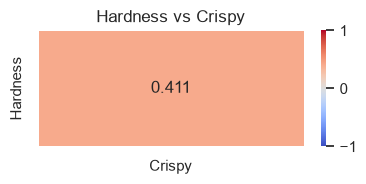

In [22]:
for col in ["Oil", "Density", "Fracture", "Hardness"]:
    corr_value = df[col].corr(df["Crispy"])

    plt.figure(figsize=(4, 2))

    sns.heatmap(
        [[corr_value]],
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        xticklabels=["Crispy"],
        yticklabels=[col],
        linewidths=0.5
    )

    plt.title(f"{col} vs Crispy")
    plt.tight_layout()
    plt.show()

In [20]:
numeric_df.corr()["Crispy"].sort_values(ascending=False)

Crispy      1.000000
Oil         0.593086
Hardness    0.411093
Density    -0.670946
Fracture   -0.843965
Name: Crispy, dtype: float64